In [1]:
# Install object detection, OCR and text-to-speech libraries.
!pip install -q ultralytics easyocr gTTS

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.
spacy 3.8.18 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.
huggingface-hub 1.33.0 requires click<9.0.0,>=8.4.2, but you have click 8.1.8 which is incompatible.


In [2]:
import random
import re
import shutil
import zipfile
import json
import xml.etree.ElementTree as ET
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image, ImageDraw

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Warning: Runtime > Change runtime type > T4 GPU select karo.")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [3]:
from google.colab import files

uploaded = files.upload()
archive_files = [
    name for name in uploaded
    if name.lower().endswith((".zip", ".tar.bz2", ".tar.gz", ".tgz"))
]

if not archive_files:
    raise ValueError("LandingLens snapshot se downloaded .zip ya .tar.bz2 dataset upload karo.")

ARCHIVE_PATH = archive_files[0]
print("Uploaded dataset archive:", ARCHIVE_PATH)

Saving Snapshot-11-05-202618_51-1793885581487.tar.bz2 to Snapshot-11-05-202618_51-1793885581487.tar.bz2
Uploaded dataset archive: Snapshot-11-05-202618_51-1793885581487.tar.bz2


In [4]:
import shutil
import tarfile

EXPORT_ROOT = Path("/content/landinglens_export")

if EXPORT_ROOT.exists():
    shutil.rmtree(EXPORT_ROOT)
EXPORT_ROOT.mkdir(parents=True)

archive_name = Path(ARCHIVE_PATH).name.lower()
if archive_name.endswith(".zip"):
    with zipfile.ZipFile(ARCHIVE_PATH, "r") as archive:
        archive.extractall(EXPORT_ROOT)
else:
    # LandingLens ka default download format: tar.bz2 (tar.gz/tgz bhi chalega).
    with tarfile.open(ARCHIVE_PATH) as archive:
        archive.extractall(EXPORT_ROOT)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
exported_images = [
    path for path in EXPORT_ROOT.rglob("*")
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
]
exported_xml = list(EXPORT_ROOT.rglob("*.xml"))

print("Images found:", len(exported_images))
print("Pascal VOC XML files found:", len(exported_xml))

if len(exported_images) != 45:
    print(f"Warning: 45 images expected, but {len(exported_images)} found.")
if not exported_xml:
    raise ValueError("XML annotations nahi mili. LandingLens se labeled snapshot export karo.")

/tmp/ipykernel_370/1214755427.py:17: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  archive.extractall(EXPORT_ROOT)


Images found: 46
Pascal VOC XML files found: 45


In [5]:
YOLO_ROOT = Path("/content/medicine_label_yolo")

if YOLO_ROOT.exists():
    shutil.rmtree(YOLO_ROOT)

for split_name in ["train", "val", "test"]:
    (YOLO_ROOT / split_name / "images").mkdir(parents=True, exist_ok=True)
    (YOLO_ROOT / split_name / "labels").mkdir(parents=True, exist_ok=True)

# Match each Pascal VOC XML with its image.
images_by_name = {}
images_by_stem = {}
for image_path in exported_images:
    images_by_name.setdefault(image_path.name, image_path)
    images_by_stem.setdefault(image_path.stem, image_path)

records = []
discovered_classes = set()

for xml_path in exported_xml:
    xml_root = ET.parse(xml_path).getroot()
    xml_filename = xml_root.findtext("filename")

    image_path = None
    if xml_filename:
        image_path = images_by_name.get(Path(xml_filename).name)
    if image_path is None:
        image_path = images_by_stem.get(xml_path.stem)

    for obj in xml_root.findall("object"):
        class_name = (obj.findtext("name") or "").strip()
        if class_name:
            discovered_classes.add(class_name)

    if image_path is not None:
        records.append((image_path, xml_path))
    else:
        print("No matching image for:", xml_path.name)

print("Matched image/XML pairs:", len(records))
print("Classes found in XML:", sorted(discovered_classes))

unexpected_classes = discovered_classes - {"medi_info"}
if unexpected_classes:
    raise ValueError(
        "Unexpected classes found: " + str(sorted(unexpected_classes))
        + ". LandingLens mein only 'medi_info' class use karo."
    )
if not records:
    raise ValueError("No image/XML pairs found.")

random.Random(SEED).shuffle(records)
total = len(records)

# Exactly 45 records give a 33/7/5 split. Other totals use similar ratios.
if total == 45:
    train_count, val_count = 33, 7
else:
    train_count = max(1, round(total * 0.74))
    val_count = max(1, round(total * 0.15))
    if train_count + val_count >= total:
        train_count = max(1, total - 2)
        val_count = 1

split_records = {
    "train": records[:train_count],
    "val": records[train_count : train_count + val_count],
    "test": records[train_count + val_count :],
}

print("Split sizes:", {name: len(items) for name, items in split_records.items()})


def convert_voc_annotation(image_path: Path, xml_path: Path, split_name: str) -> int:
    xml_root = ET.parse(xml_path).getroot()
    width_text = xml_root.findtext("size/width")
    height_text = xml_root.findtext("size/height")

    if width_text and height_text:
        image_width = int(float(width_text))
        image_height = int(float(height_text))
    else:
        with Image.open(image_path) as image:
            image_width, image_height = image.size

    yolo_lines = []

    for obj in xml_root.findall("object"):
        class_name = (obj.findtext("name") or "").strip()
        if class_name != "medi_info":
            continue

        box = obj.find("bndbox")
        if box is None:
            continue

        xmin = float(box.findtext("xmin"))
        ymin = float(box.findtext("ymin"))
        xmax = float(box.findtext("xmax"))
        ymax = float(box.findtext("ymax"))

        xmin = max(0.0, min(xmin, image_width - 1))
        ymin = max(0.0, min(ymin, image_height - 1))
        xmax = max(0.0, min(xmax, image_width))
        ymax = max(0.0, min(ymax, image_height))

        if xmax <= xmin or ymax <= ymin:
            continue

        x_center = ((xmin + xmax) / 2.0) / image_width
        y_center = ((ymin + ymax) / 2.0) / image_height
        box_width = (xmax - xmin) / image_width
        box_height = (ymax - ymin) / image_height

        # YOLO line: class_id x_center y_center width height
        yolo_lines.append(
            f"0 {x_center:.6f} {y_center:.6f} "
            f"{box_width:.6f} {box_height:.6f}"
        )

    output_image = YOLO_ROOT / split_name / "images" / image_path.name
    output_label = YOLO_ROOT / split_name / "labels" / f"{image_path.stem}.txt"
    shutil.copy2(image_path, output_image)
    output_label.write_text(chr(10).join(yolo_lines), encoding="utf-8")
    return len(yolo_lines)


total_boxes = 0
images_without_boxes = []

for split_name, items in split_records.items():
    for image_path, xml_path in items:
        box_count = convert_voc_annotation(image_path, xml_path, split_name)
        total_boxes += box_count
        if box_count == 0:
            images_without_boxes.append(image_path.name)

DATA_YAML = YOLO_ROOT / "data.yaml"
DATA_YAML.write_text(
    chr(10).join(
        [
            f"path: {YOLO_ROOT}",
            "train: train/images",
            "val: val/images",
            "test: test/images",
            "",
            "names:",
            "  0: medi_info",
        ]
    ),
    encoding="utf-8",
)

print("Total medi_info boxes:", total_boxes)
print("Images without boxes:", images_without_boxes)
print("Dataset YAML:" + chr(10) + DATA_YAML.read_text())

if images_without_boxes:
    print("Warning: In images ko LandingLens mein check karke medi_info box add karo.")

Matched image/XML pairs: 45
Classes found in XML: ['medi_info']
Split sizes: {'train': 33, 'val': 7, 'test': 5}
Total medi_info boxes: 52
Images without boxes: []
Dataset YAML:
path: /content/medicine_label_yolo
train: train/images
val: val/images
test: test/images

names:
  0: medi_info


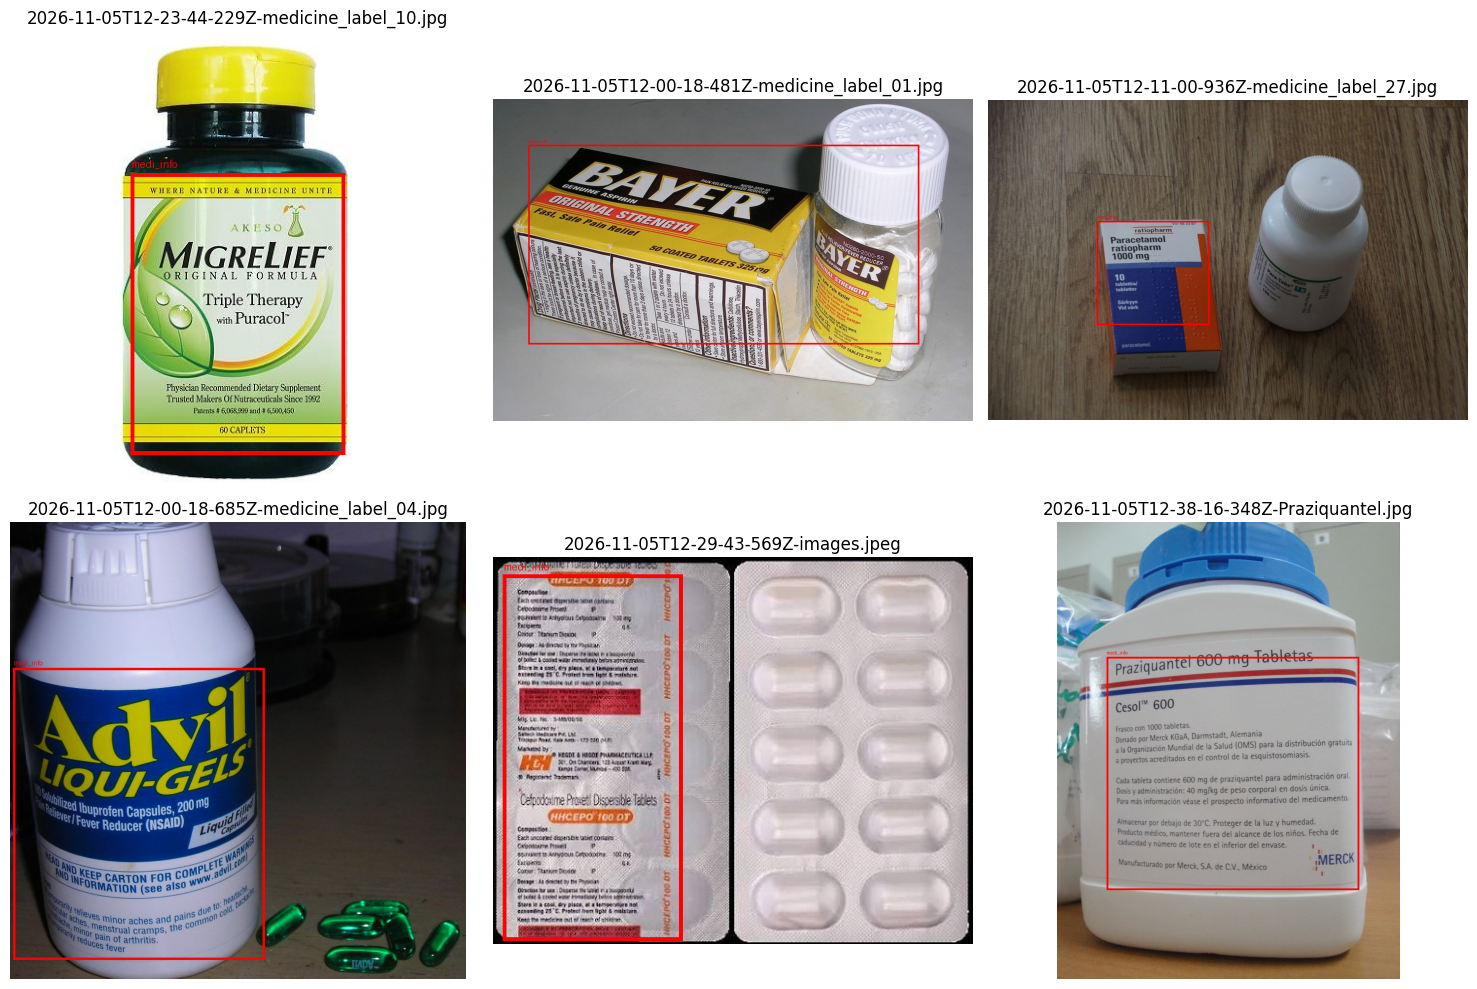

In [6]:
train_images = [
    path for path in (YOLO_ROOT / "train" / "images").iterdir()
    if path.suffix.lower() in IMAGE_EXTENSIONS
]
sample_count = min(6, len(train_images))
sample_images = random.Random(SEED).sample(train_images, sample_count)

figure, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = np.array(axes).reshape(-1)
for axis in axes:
    axis.axis("off")

for axis, image_path in zip(axes, sample_images):
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    image_width, image_height = image.size
    label_path = YOLO_ROOT / "train" / "labels" / f"{image_path.stem}.txt"

    for line in label_path.read_text().splitlines():
        values = line.split()
        _, x_center, y_center, box_width, box_height = map(float, values)

        xmin = (x_center - box_width / 2) * image_width
        ymin = (y_center - box_height / 2) * image_height
        xmax = (x_center + box_width / 2) * image_width
        ymax = (y_center + box_height / 2) * image_height

        draw.rectangle([xmin, ymin, xmax, ymax], outline="red", width=4)
        draw.text((xmin, max(0, ymin - 15)), "medi_info", fill="red")

    axis.imshow(image)
    axis.set_title(image_path.name)
    axis.axis("off")

plt.tight_layout()
plt.show()

In [7]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

training_results = model.train(
    data=str(DATA_YAML),
    epochs=80,
    imgsz=640,
    batch=8,
    patience=20,
    workers=2,
    cache=True,
    seed=SEED,
    project="/content/runs",
    name="medicine_label_detector",
    exist_ok=True,
    plots=True,
    # Mild augmentations; flips are disabled because mirrored text is unrealistic.
    degrees=8,
    translate=0.08,
    scale=0.25,
    perspective=0.0005,
    hsv_h=0.01,
    hsv_s=0.30,
    hsv_v=0.25,
    fliplr=0.0,
    flipud=0.0,
    mosaic=0.40,
)

RUN_DIR = Path("/content/runs/medicine_label_detector")
BEST_MODEL = RUN_DIR / "weights" / "best.pt"
print("Best model:", BEST_MODEL)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/medicine_label_yolo/data.yaml, degrees=8, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.

results.png


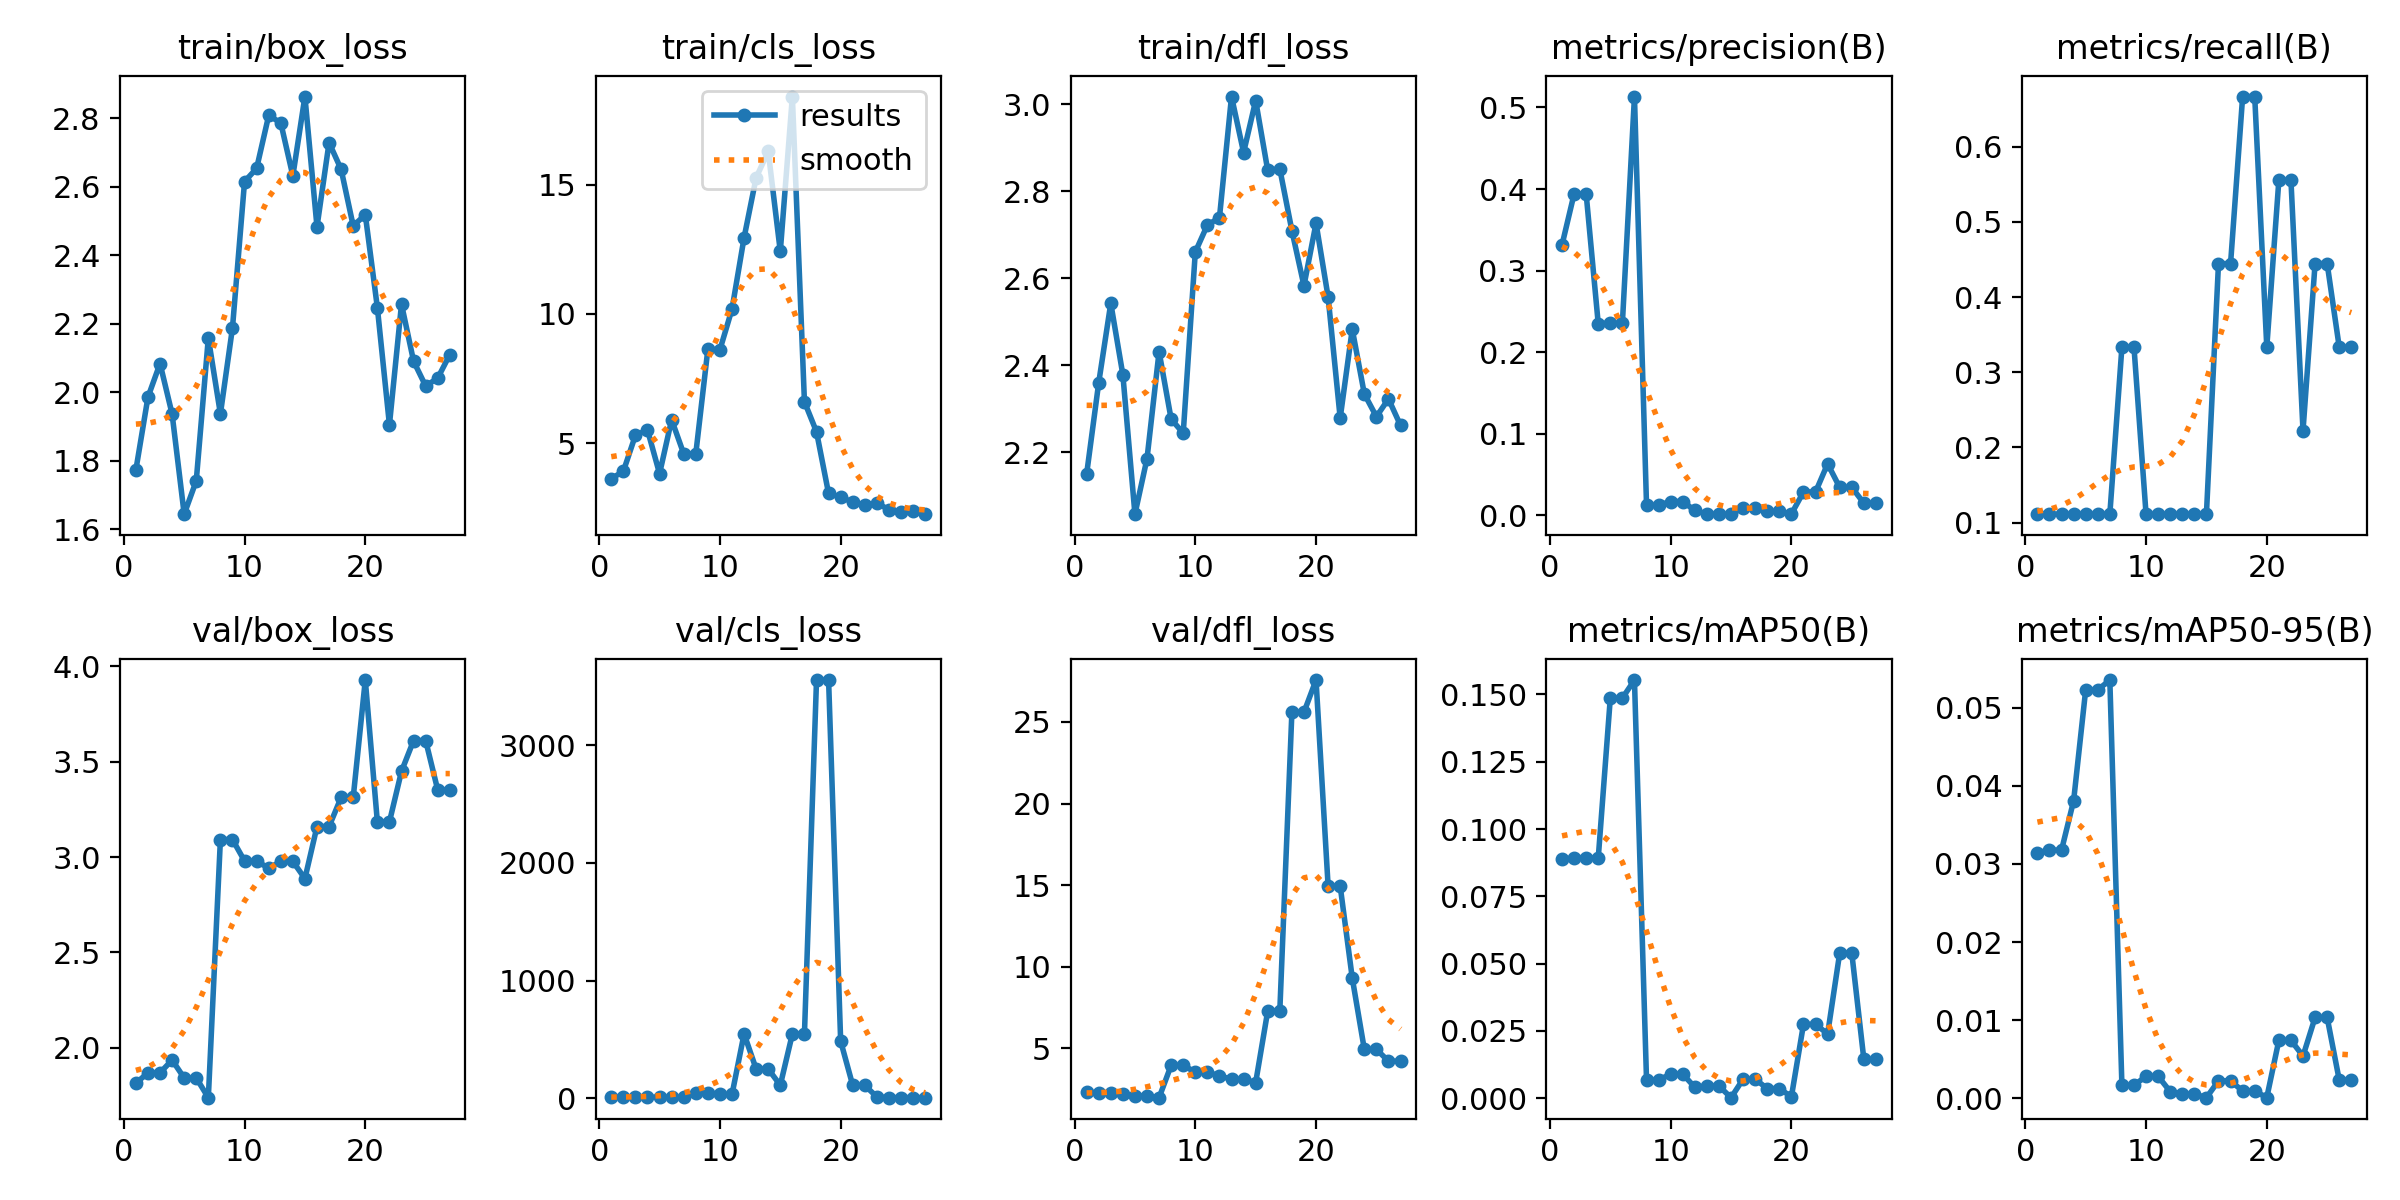

confusion_matrix.png


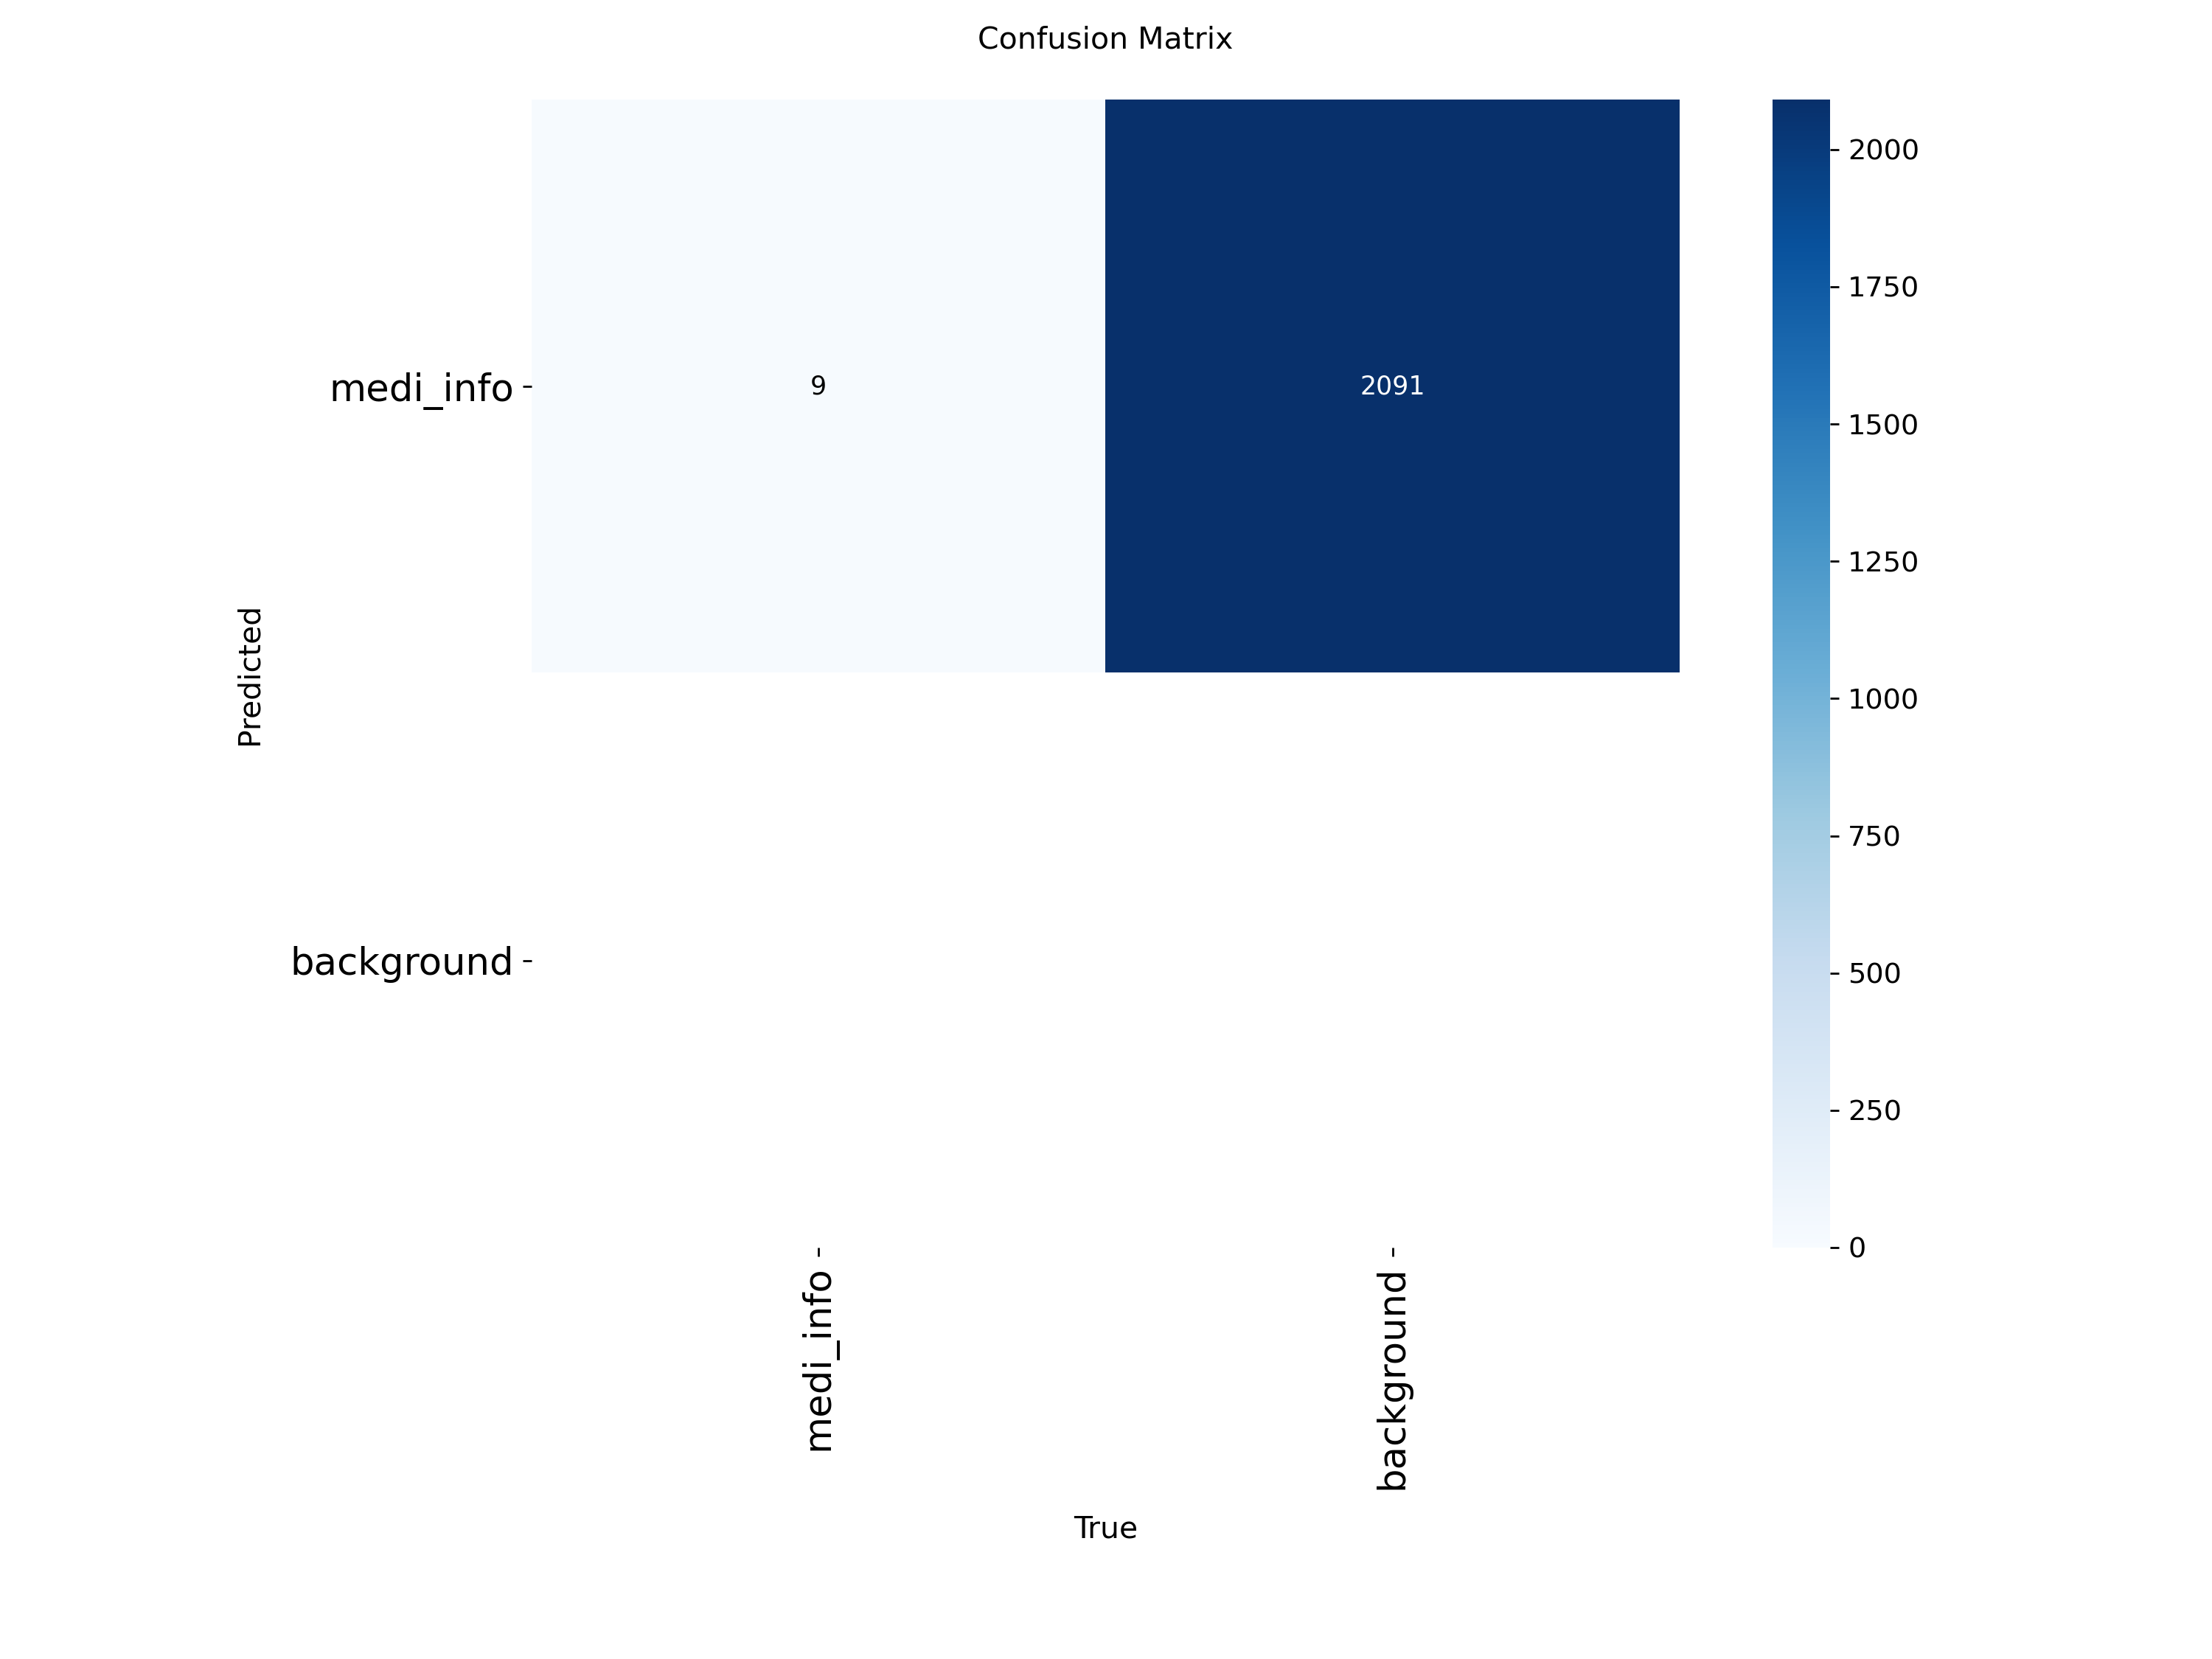

In [8]:
from IPython.display import Image as DisplayImage, display

for filename in ["results.png", "confusion_matrix.png", "PR_curve.png", "F1_curve.png"]:
    plot_path = RUN_DIR / filename
    if plot_path.exists():
        print(filename)
        display(DisplayImage(filename=str(plot_path)))

In [9]:
detector = YOLO(str(BEST_MODEL))
metrics = detector.val(data=str(DATA_YAML), split="test", conf=0.25, plots=True)

print(f"mAP@50:    {metrics.box.map50:.4f}")
print(f"mAP@50-95: {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")
print("Note: Test set bahut small hai, isliye metrics unstable ho sakti hain.")

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2392.8±1638.7 MB/s, size: 448.1 KB)
val: Scanning /content/medicine_label_yolo/test/labels... 5 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5/5 1.4Kit/s 0.0s
val: New cache created: /content/medicine_label_yolo/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 5.8it/s 0.2s
                   all          5          5      0.199        0.4      0.163     0.0502
Speed: 0.4ms preprocess, 11.5ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/runs/detect/val
mAP@50:    0.1632
mAP@50-95: 0.0502
Precision: 0.1990
Recall:    0.4000
Note: Test set bahut small hai, isliye metrics unstable ho sakti hain.


In [10]:
test_upload = files.upload()
test_images = [
    filename for filename in test_upload
    if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"))
]

if not test_images:
    raise ValueError("Ek test medicine-bottle image upload karo.")

TEST_IMAGE = test_images[0]
print("Test image:", TEST_IMAGE)

Saving images (4).jpeg to images (4).jpeg
Test image: images (4).jpeg


Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompleteDetection 1
  Confidence: 0.54
  OCR text: No confident text
Detection 2
  Confidence: 0.393
  OCR text: No confident text
Detection 3
  Confidence: 0.361
  OCR text: No confident text
Detection 4
  Confidence: 0.289
  OCR text: No confident text
Detection 5
  Confidence: 0.274
  OCR text: CLINICALLY PROVEN BLOOD" SugaR


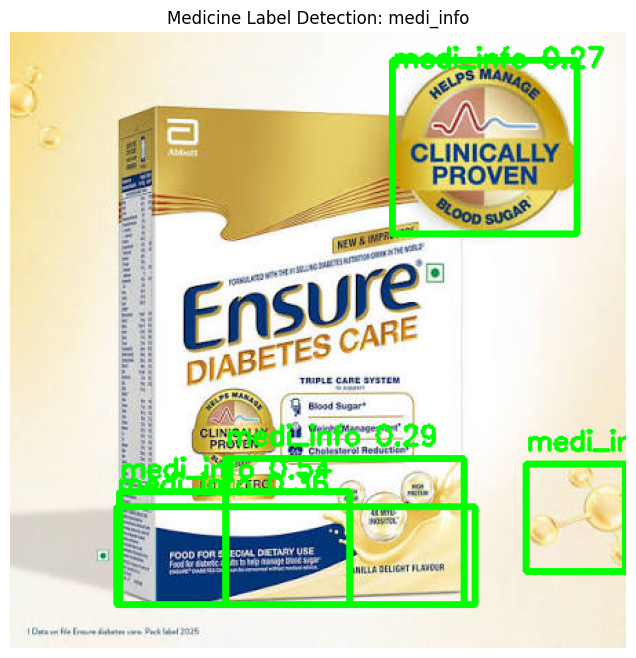


Complete extracted text:
CLINICALLY PROVEN BLOOD" SugaR


In [11]:
import easyocr

OUTPUT_DIR = Path("/content/medicine_label_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

detector = YOLO(str(BEST_MODEL))
ocr_reader = easyocr.Reader(["en"], gpu=torch.cuda.is_available())

prediction = detector.predict(
    source=TEST_IMAGE,
    conf=0.25,
    imgsz=640,
    verbose=False,
)[0]

original_image = cv2.imread(TEST_IMAGE)
if original_image is None:
    raise ValueError("Test image read nahi ho rahi.")

annotated_image = original_image.copy()
image_height, image_width = original_image.shape[:2]
detections = []

if prediction.boxes is None or len(prediction.boxes) == 0:
    print("medi_info detect nahi hua. Clear, close aur glare-free image try karo.")
else:
    for index, box in enumerate(prediction.boxes, start=1):
        x1, y1, x2, y2 = map(int, box.xyxy[0].cpu().tolist())
        detection_confidence = float(box.conf[0].cpu())

        x1 = max(0, min(x1, image_width - 1))
        y1 = max(0, min(y1, image_height - 1))
        x2 = max(0, min(x2, image_width))
        y2 = max(0, min(y2, image_height))

        crop = original_image[y1:y2, x1:x2]
        if crop.size == 0:
            continue

        # Upscaling generally helps OCR on small printed text.
        scale = 2.0
        enlarged_crop = cv2.resize(
            crop,
            None,
            fx=scale,
            fy=scale,
            interpolation=cv2.INTER_CUBIC,
        )

        ocr_results = ocr_reader.readtext(
            enlarged_crop,
            detail=1,
            paragraph=False,
        )

        accepted_lines = []
        for ocr_box, text, ocr_confidence in ocr_results:
            if ocr_confidence >= 0.25 and text.strip():
                accepted_lines.append(
                    {"text": text.strip(), "confidence": float(ocr_confidence)}
                )

        extracted_text = " ".join(item["text"] for item in accepted_lines)
        crop_path = OUTPUT_DIR / f"medi_info_crop_{index:02d}.jpg"
        cv2.imwrite(str(crop_path), crop)

        detections.append(
            {
                "detection": index,
                "class": "medi_info",
                "detection_confidence": detection_confidence,
                "box_xyxy": [x1, y1, x2, y2],
                "ocr_lines": accepted_lines,
                "text": extracted_text,
                "crop": str(crop_path),
            }
        )

        cv2.rectangle(annotated_image, (x1, y1), (x2, y2), (0, 255, 0), 3)
        cv2.putText(
            annotated_image,
            f"medi_info {detection_confidence:.2f}",
            (x1, max(25, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            (0, 255, 0),
            2,
        )

        print(f"Detection {index}")
        print("  Confidence:", round(detection_confidence, 3))
        print("  OCR text:", extracted_text or "No confident text")

ANNOTATED_PATH = OUTPUT_DIR / "annotated_prediction.jpg"
cv2.imwrite(str(ANNOTATED_PATH), annotated_image)

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Medicine Label Detection: medi_info")
plt.show()

FULL_TEXT = " ".join(item["text"] for item in detections if item["text"]).strip()
print(); print("Complete extracted text:"); print(FULL_TEXT or "No text extracted")

In [12]:
strength_pattern = re.compile(
    r"\b\d+(?:\.\d+)?\s*(?:mcg|mg|g|ml|mL|%|mg/ml|mg/mL)\b",
    re.IGNORECASE,
)
expiry_pattern = re.compile(
    r"\b(?:EXP|EXPIRY|EXPIRES)?\s*[:\-]?\s*"
    r"((?:0?[1-9]|1[0-2])[/-](?:\d{2}|\d{4}))\b",
    re.IGNORECASE,
)
identifier_pattern = re.compile(
    r"\b(?:LOT|BATCH|NDC)\s*[:#\-]?\s*([A-Z0-9\-]+)\b",
    re.IGNORECASE,
)

extracted_information = {
    "raw_text": FULL_TEXT,
    "strengths": strength_pattern.findall(FULL_TEXT),
    "expiry_dates": expiry_pattern.findall(FULL_TEXT),
    "batch_or_ndc": identifier_pattern.findall(FULL_TEXT),
    "detections": detections,
}

INFO_PATH = OUTPUT_DIR / "extracted_information.json"
INFO_PATH.write_text(
    json.dumps(extracted_information, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

print(json.dumps({
    "raw_text": extracted_information["raw_text"],
    "strengths": extracted_information["strengths"],
    "expiry_dates": extracted_information["expiry_dates"],
    "batch_or_ndc": extracted_information["batch_or_ndc"],
}, indent=2, ensure_ascii=False))

{
  "raw_text": "CLINICALLY PROVEN BLOOD\" SugaR",
  "strengths": [],
  "expiry_dates": [],
  "batch_or_ndc": []
}


In [13]:
from gtts import gTTS
from IPython.display import Audio, display

if FULL_TEXT:
    speech_text = "The medicine label information reads: " + FULL_TEXT
    AUDIO_PATH = OUTPUT_DIR / "medicine_label_audio.mp3"
    gTTS(text=speech_text, lang="en").save(str(AUDIO_PATH))
    display(Audio(str(AUDIO_PATH), autoplay=False))
else:
    print("Label text unclear hai. User ko closer, sharper image lene ko bolo.")

In [14]:
# Package inference outputs.
OUTPUT_ZIP = shutil.make_archive(
    "/content/medicine_label_results",
    "zip",
    root_dir=OUTPUT_DIR,
)

print("Downloading trained YOLO model...")
files.download(str(BEST_MODEL))

print("Downloading OCR and prediction outputs...")
files.download(OUTPUT_ZIP)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
# LandingLens cloud credentials — no SDK installation required.
import getpass
import uuid

ENDPOINT_ID = "85e22679-7a6b-4584-9aaf-704745518b5f"  # medi_label

PREDICTION_URL = (
    "https://predict.app.landing.ai/inference/v1/predict"
    f"?endpoint_id={ENDPOINT_ID}"
)

# Colab Secret try karo; nahi mile to hidden prompt khulega.
API_KEY = ""

try:
    from google.colab import userdata
    API_KEY = userdata.get("LANDINGAI_API_KEY") or ""
except Exception:
    pass

if not API_KEY:
    API_KEY = getpass.getpass("LandingLens API key paste karo: ").strip()

if not API_KEY:
    raise ValueError("LandingLens API key required hai.")

uuid.UUID(ENDPOINT_ID)

print("Endpoint:", "medi_label")
print("Endpoint UUID:", ENDPOINT_ID)
print("API key loaded:", API_KEY.startswith("land_"))
print("No LandingLens SDK installation required.")

LandingLens API key paste karo: ··········
Endpoint: medi_label
Endpoint UUID: 85e22679-7a6b-4584-9aaf-704745518b5f
API key loaded: True
No LandingLens SDK installation required.


Cloud inference image: images (4).jpeg
Cloud predictions: 1
Prediction 1: label=medi_info score=0.960 bbox=(109, 138, 308, 397)
LandingLens latency metrics:
{
  "preprocess_s": 0.008587360382080078,
  "infer_s": 0.2907228469848633,
  "postprocess_s": 0.000324249267578125,
  "serialize_s": 0.0001418590545654297,
  "input_conversion_s": 0.0025382041931152344,
  "model_loading_s": 7.82012939453125e-05
}
HTTP round-trip time: 0.650 seconds
Detection 1: score=0.960, OCR=CLINICALLY PrOVEN Ensure CARE DIABETES =


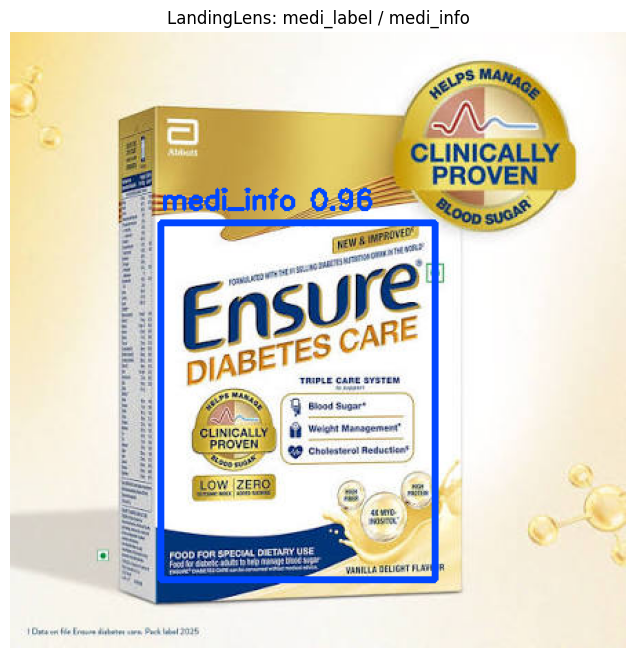

Saved: /content/medicine_label_cloud_outputs/cloud_extracted_information.json


In [20]:
from pathlib import Path
from PIL import Image
from gtts import gTTS
from IPython.display import Audio, display

import cv2
import easyocr
import json
import matplotlib.pyplot as plt
import mimetypes
import numpy as np
import requests
import time
import torch

# Select test image
cloud_candidates = []

if globals().get("TEST_IMAGE"):
    cloud_candidates.append(Path(TEST_IMAGE))

cloud_candidates.extend(
    Path(path) for path in sorted(globals().get("exported_images", []))
)

cloud_image_path = next(
    (path for path in cloud_candidates if path.exists()),
    None,
)

if cloud_image_path is None:
    raise ValueError(
        "Pehle Section 6 mein test image upload karo."
    )

print("Cloud inference image:", cloud_image_path)

# LandingLens REST API inference
mime_type = mimetypes.guess_type(cloud_image_path.name)[0] or "image/jpeg"
start_time = time.perf_counter()

with cloud_image_path.open("rb") as image_file:
    response = requests.post(
        PREDICTION_URL,
        headers={"apikey": API_KEY},
        files={
            "file": (
                cloud_image_path.name,
                image_file,
                mime_type,
            )
        },
        timeout=120,
    )

roundtrip_s = time.perf_counter() - start_time

if not response.ok:
    raise RuntimeError(
        f"LandingLens API error {response.status_code}: "
        f"{response.text[:1200]}"
    )

cloud_response = response.json()
raw_predictions = cloud_response.get("backbonepredictions") or {}
cloud_predictions = []

for prediction_id, raw_prediction in raw_predictions.items():
    coordinates = raw_prediction.get("coordinates") or {}

    if not all(
        name in coordinates
        for name in ("xmin", "ymin", "xmax", "ymax")
    ):
        continue

    cloud_predictions.append(
        {
            "id": prediction_id,
            "label_name": raw_prediction.get("labelName", ""),
            "score": float(raw_prediction.get("score", 0.0)),
            "bboxes": (
                coordinates["xmin"],
                coordinates["ymin"],
                coordinates["xmax"],
                coordinates["ymax"],
            ),
        }
    )

cloud_predictions.sort(
    key=lambda prediction: prediction["score"],
    reverse=True,
)

print(f"Cloud predictions: {len(cloud_predictions)}")

for index, prediction in enumerate(cloud_predictions, start=1):
    print(
        f"Prediction {index}: "
        f"label={prediction['label_name']} "
        f"score={prediction['score']:.3f} "
        f"bbox={prediction['bboxes']}"
    )

cloud_latency = cloud_response.get("latency") or {}
print("LandingLens latency metrics:")
print(json.dumps(cloud_latency, indent=2))
print(f"HTTP round-trip time: {roundtrip_s:.3f} seconds")

# EasyOCR setup
if "ocr_reader" not in globals():
    ocr_reader = easyocr.Reader(
        ["en"],
        gpu=torch.cuda.is_available(),
    )

CLOUD_OUTPUT_DIR = Path("/content/medicine_label_cloud_outputs")
CLOUD_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

cloud_pil = Image.open(str(cloud_image_path)).convert("RGB")
annotated_cloud = cv2.cvtColor(
    np.asarray(cloud_pil),
    cv2.COLOR_RGB2BGR,
)

image_height, image_width = annotated_cloud.shape[:2]
cloud_detections = []

# Crop medi_info boxes and run OCR
for index, prediction in enumerate(cloud_predictions, start=1):
    if prediction["label_name"] != "medi_info":
        continue

    x1, y1, x2, y2 = map(int, prediction["bboxes"])

    x1 = max(0, min(x1, image_width - 1))
    y1 = max(0, min(y1, image_height - 1))
    x2 = max(0, min(x2, image_width))
    y2 = max(0, min(y2, image_height))

    crop = annotated_cloud[y1:y2, x1:x2]

    if crop.size == 0:
        continue

    enlarged_crop = cv2.resize(
        crop,
        None,
        fx=2.0,
        fy=2.0,
        interpolation=cv2.INTER_CUBIC,
    )

    ocr_results = ocr_reader.readtext(
        enlarged_crop,
        detail=1,
        paragraph=False,
    )

    ocr_lines = [
        {
            "text": text.strip(),
            "confidence": float(confidence),
        }
        for _, text, confidence in ocr_results
        if confidence >= 0.25 and text.strip()
    ]

    cloud_text = " ".join(
        item["text"] for item in ocr_lines
    )

    crop_path = (
        CLOUD_OUTPUT_DIR
        / f"cloud_medi_info_crop_{index:02d}.jpg"
    )

    cv2.imwrite(str(crop_path), crop)

    cloud_detections.append(
        {
            "detection": index,
            "class": "medi_info",
            "detection_confidence": prediction["score"],
            "box_xyxy": [x1, y1, x2, y2],
            "ocr_lines": ocr_lines,
            "text": cloud_text,
            "crop": str(crop_path),
        }
    )

    cv2.rectangle(
        annotated_cloud,
        (x1, y1),
        (x2, y2),
        (255, 70, 0),
        3,
    )

    cv2.putText(
        annotated_cloud,
        f"medi_info {prediction['score']:.2f}",
        (x1, max(25, y1 - 10)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.65,
        (255, 70, 0),
        2,
    )

    print(
        f"Detection {index}: "
        f"score={prediction['score']:.3f}, "
        f"OCR={cloud_text or 'No confident text'}"
    )

# Display annotated result
CLOUD_ANNOTATED_PATH = (
    CLOUD_OUTPUT_DIR / "cloud_annotated_prediction.jpg"
)

cv2.imwrite(str(CLOUD_ANNOTATED_PATH), annotated_cloud)

plt.figure(figsize=(12, 8))
plt.imshow(
    cv2.cvtColor(
        annotated_cloud,
        cv2.COLOR_BGR2RGB,
    )
)
plt.axis("off")
plt.title("LandingLens: medi_label / medi_info")
plt.show()

# Save JSON results
CLOUD_INFO_PATH = (
    CLOUD_OUTPUT_DIR / "cloud_extracted_information.json"
)

CLOUD_INFO_PATH.write_text(
    json.dumps(
        {
            "endpoint_id": ENDPOINT_ID,
            "model_id": cloud_response.get("model_id"),
            "image": str(cloud_image_path),
            "latency_metrics": cloud_latency,
            "http_roundtrip_s": roundtrip_s,
            "detections": cloud_detections,
        },
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

print("Saved:", CLOUD_INFO_PATH)